# Gaussian foreground screen: the Faraday-off/on visibility

**Step 1 for Christian's review.** This notebook specifies a physical toy
ensemble and derives the mean and covariance of the original paired
Faraday-off/on visibility. It executes algebraic limits and one-dimensional
integration checks. It does **not** validate spatial screen simulations,
model the Galaxy, or update the detection forecast.

Rebuild and execute from the repository root with
`.venv/bin/python scripts/gaussian_screen_step1.py`. The executor uses that
same Python for the kernel. No external maps, real beam, or random seeds are
needed. Figures are also regenerated under `report/figures/`; numerical
products and the source/configuration fingerprint are saved under
`generated_data/gaussian_screen_step1/`.

Read the [specification](../docs/specs/2026-10-15-gaussian-screen-step1.md)
and [implementation and step-2
plan](../docs/plans/2026-10-15-gaussian-screen-step1.md).
The mathematical review in [paper preparation](../docs/paper-preparation.md)
is the starting point. The technical claim here is conditional on the model
below; no literature-based Galactic parameter estimate is used.

## 1. Physical ensemble, fixed quantities, units and frame

At one fixed pointing, draw a **single physical foreground screen** and use
it at every frequency. The intrinsic source, source angle, beam and ideal
receiver are deterministic and fixed. The off calculation sets its rotation
to zero while keeping everything else identical. Ensemble averaging describes
possible screens, not a screen that redraws between measurements.

The toy geometry is an infinite tangent plane about zenith. Coordinates
$\boldsymbol\theta=(\theta_E,\theta_N)$ are in radians in a fixed East/North
polarization basis. Curvature, parallel transport, horizon and lunar motion
are excluded. At a thin screen distance $d=100\,\mathrm{pc}$,
$\mathbf r=d\boldsymbol\theta$. Adopt a stationary real Gaussian depth field
$\phi(\mathbf r)$ with
\[
\langle\phi\rangle=m,\quad
K_\phi(h)=\langle\delta\phi(\mathbf r)\delta\phi(\mathbf r')\rangle
=\sigma_\phi^2 e^{-h^2/(2\ell^2)},\quad h=|\mathbf r-\mathbf r'|.
\]
Baseline $m=0.01\,\mathrm{rad\,m^{-2}}$,
$\sigma_\phi=0.02\,\mathrm{rad\,m^{-2}}$, and **physical**
$\ell=0.5\,\mathrm{pc}$.
The angular correlation scale is $\ell/d$, defined by correlation $e^{-1/2}$.
For $K(h)=\int d^2k\,S(k)e^{i\mathbf k\cdot\mathbf h}/(2\pi)^2$,
\[
S(k)=2\pi\sigma_\phi^2\ell^2 e^{-\ell^2 k^2/2}\geq0,
\quad \int\frac{d^2k}{(2\pi)^2}S(k)=\sigma_\phi^2.
\]
This proves admissibility on the plane. The structure function is
$D_\phi(h)=2\sigma_\phi^2[1-\rho(h)]$, $\rho=e^{-h^2/(2\ell^2)}$.
The model is smooth, and is not a claimed Galactic turbulence spectrum.
$\ell\to\infty$ is one random constant depth over the entire source.

Use the deterministic Rayleigh-Jeans source and normalized power beam
\[
I_0=I_{\rm ref} f_i e^{-\theta^2/(2s_{\rm src}^2)},\quad
P_0=Q+iU=P_{\rm ref}f_i e^{2i\chi}e^{-\theta^2/(2s_{\rm src}^2)},\quad
B=\frac{e^{-\theta^2/(2s_{\rm beam}^2)}}{2\pi s_{\rm beam}^2}.
\]
$I_{\rm ref}=2$ K, $P_{\rm ref}=1$ K, $\chi=20^\circ$,
$s_{\rm src}=1.5^\circ$, $s_{\rm beam}=1^\circ$ (standard deviations),
$f_i=(\nu_i/30\,\mathrm{MHz})^{\beta}$, with $\beta$ imported from
`config.BETA_QU`. Stokes $V=0$, and $I\geq |P|$ everywhere.
$B$ has inverse-solid-angle units under $d\Omega\simeq d^2\theta$.
The source is smooth in frequency; rapid structure comes from rotation.

The 10--50 MHz sweep consists of **monochromatic** samples with the same
achromatic toy beam; it is not the actual broad-band LuSEE beam. There are
no channel responses or noise in this calculation. All axes and moments
refer to beam-averaged K (or K$^2$), not loaded voltage covariance.

In [1]:
import os

os.environ.setdefault("JAX_ENABLE_X64", "1")  # before project/JAX imports
os.environ.setdefault("MPLBACKEND", "Agg")
from dataclasses import asdict, replace
from datetime import datetime, timezone
from pathlib import Path
import hashlib
import importlib.metadata as metadata
import json
import platform
import resource
import subprocess
import sys
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
from numpy.polynomial.hermite import hermgauss
from scipy.integrate import IntegrationWarning
import nbformat

from lusee_faraday.config import BETA_QU
from lusee_faraday.conventions import lambda_squared, faraday_phase_cosmo
from lusee_faraday.gaussian_screen import (
    ScreenModel,
    SeparationQuadrature,
    source_terms,
    centered_branch,
    branch_second_special,
    visibility_moments,
)

warnings.simplefilter("error", IntegrationWarning)
ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "src/lusee_faraday").is_dir()
    and (path / "pyproject.toml").is_file()
)
# Enable embedded figure outputs even when launched with MPLBACKEND=Agg.
get_ipython().run_line_magic("matplotlib", "inline")
model = ScreenModel()
numerical = SeparationQuadrature()
started = time.monotonic()
checks = {}
plt.rcParams.update({"font.size": 10, "figure.dpi": 120})
print("Physical model:", json.dumps(asdict(model), indent=2))
print("Numerical configuration:", asdict(numerical))
print(f"Effective weight width w = {model.weight_sigma_pc:.6g} pc")
print(
    f"Angular correlation scale = "
    f"{np.rad2deg(model.correlation_pc/model.distance_pc):.6g} deg"
)
print("No pixel size or pixel count appears in this configuration.")

Physical model: {
  "distance_pc": 100.0,
  "correlation_pc": 0.5,
  "mean_depth": 0.01,
  "sigma_depth": 0.02,
  "beam_sigma_deg": 1.0,
  "source_sigma_deg": 1.5,
  "i_ref_k": 2.0,
  "p_ref_k": 1.0,
  "angle_deg": 20.0,
  "ref_mhz": 30.0,
  "beta": -2.8,
  "jones_angle_deg": 45.0,
  "jones_phase_deg": 60.0
}
Numerical configuration: {'epsabs': 2e-11, 'epsrel': 2e-10, 'upper_u': 40.0}
Effective weight width w = 1.4522 pc
Angular correlation scale = 0.286479 deg
No pixel size or pixel count appears in this configuration.


## 2. A complex visibility with both polarization branches

The COSMO convention is $P_{\rm on}=P_0e^{+2i\phi\lambda^2}$, using
`conventions.lambda_squared` and `faraday_phase_cosmo`; no IAU conversion
is applied in the plane. Ideal Jones rows
$j_p=(1,0)$ and $j_q=(\cos\psi,e^{i\delta}\sin\psi)$,
$\psi=45^\circ$, $\delta=60^\circ$, define a complex cross visibility.
For $\langle EE^\dagger\rangle=\frac12\left(\begin{smallmatrix}
I+Q&U\\U&I-Q\end{smallmatrix}\right)$,
\[
V=\int d^2\theta\,B(k_I I+k_Q Q+k_U U),\quad
k_I=k_Q=\tfrac12\cos\psi,\quad k_U=\tfrac12 e^{-i\delta}\sin\psi.
\]
Both ports share the spatial beam. The brightness coherency is positive
semidefinite. Loading is unity and frozen, thermal terms vanish. This
realizable ideal pair is not the actual four-port response.

Combining source and beam gives
\[
\eta=\frac{s_{\rm src}^2}{s_{\rm src}^2+s_{\rm beam}^2},\quad
w=d(s_{\rm src}^{-2}+s_{\rm beam}^{-2})^{-1/2},\quad
W(\mathbf r)=\frac{e^{-r^2/(2w^2)}}{2\pi w^2},\quad \int W\,d^2r=1.
\]
With $x_i=\lambda_i^2$ in m$^2$, and $s\in\{+1,-1\}$, set
\[
Z_s(i)=\int d^2r\,W(\mathbf r)e^{2isx_i\phi(\mathbf r)},\quad
b_s(i)=\eta P_{\rm ref}f_i e^{2is\chi}\frac{k_Q-is k_U}{2},\quad
v_I(i)=\eta I_{\rm ref}f_i k_I.
\]
The paired quantities are
\[
V_{\rm on}(i)=v_I(i)+\sum_s b_s(i)Z_s(i),\qquad
V_{\rm off}(i)=v_I(i)+\sum_s b_s(i).
\]
$Z_-=Z_+^*$, but generally $b_-\ne b_+^*$. Thus replacing the visibility
by the real part of one branch would lose information. The deterministic
intensity contribution is retained and cancels in $\Delta=V_{\rm on}-V_{\rm
off}$.

## 3. Gaussian phase average and all second moments

For any real Gaussian vector, its characteristic function is
$\langle e^{i\mathbf a^T\boldsymbol\phi}\rangle
=\exp(i\mathbf a^T\mathbf m-\mathbf a^T K\mathbf a/2)$.
Apply it once to the **same physical screen** at the two directions:
\[
a_s(i)=\langle Z_s(i)\rangle=e^{2ismx_i-2\sigma_\phi^2x_i^2},
\]
\[
G_{st}(i,j;h)=\left\langle e^{2i[sx_i\phi(\mathbf r)-tx_j\phi(\mathbf
r')]}\right\rangle
=e^{2im(sx_i-tx_j)}
e^{-2\sigma_\phi^2[x_i^2+x_j^2-2stx_ix_j\rho(h)]}.
\]
For $s=t$, this is $e^{2ism(x_i-x_j)}
e^{-2\sigma_\phi^2(x_i-x_j)^2}e^{-2x_ix_jD_\phi(h)}$.
At equal frequency the last kernel is $e^{-2\lambda^4D_\phi(h)}$.
Opposite-branch terms use $st=-1$ and must also be kept.

Define $M_{st}=\int d^2r\,d^2r'\,WW'G_{st}$ and
$K_{st}=M_{st}-a_s(i)a_t(j)^*$. Then
\[
\mu_{\rm on}(i)=v_I(i)+\sum_s b_s(i)a_s(i),\quad
C_{ij}=\sum_{st}b_s(i)b_t(j)^*K_{st}(i,j),
\]
\[
\langle V_{{\rm on},i}V_{{\rm on},j}^*\rangle
=C_{ij}+\mu_{{\rm on},i}\mu_{{\rm on},j}^*,\quad
\langle V_{{\rm off},i}V_{{\rm off},j}^*\rangle=V_{{\rm off},i}V_{{\rm
off},j}^*,
\]
\[
\langle V_{{\rm on},i}V_{{\rm off},j}^*\rangle
=\mu_{{\rm on},i}V_{{\rm off},j}^*.
\]
The off mean is $V_{\rm off}$, and its centered covariance and centered
on/off cross-covariance are zero because off is deterministic.
For the paired difference,
\[
\mu_\Delta=\mu_{\rm on}-V_{\rm off},\quad C_\Delta=C,\quad
\langle\Delta_i\Delta_j^*\rangle=C_{ij}+\mu_{\Delta,i}\mu_{\Delta,j}^*,
\]
\[
\boxed{\langle|V_{{\rm on},i}-V_{{\rm off},i}|^2\rangle
=C_{ii}+|\mu_{{\rm on},i}-V_{{\rm off},i}|^2.}
\]
A depolarized on mean still leaves the second term. Mean polarization power
$|\langle P\rangle|^2$ cannot replace $\langle|P|^2\rangle$.
If off were uncertain, its covariance and joint covariance with on would
enter; this notebook does not assume that more general model.

For completeness the nonconjugated centered moment is
$J_{ij}=\langle\delta V_i\delta V_j\rangle
=\sum_{st}b_s(i)b_t(j)K_{s,-t}(i,j)$, with raw moment
$J_{ij}+\mu_i\mu_j$. The visibility distribution need not be Gaussian or
circular. $C$ and $J$ specify the second moments of its real/imaginary parts.

## 4. Reduce the angular integral before evaluating it

The autocorrelation of the normalized Gaussian weight is
$A_W(h)=\int W(\mathbf r)W(\mathbf r+\mathbf h)d^2r
=e^{-h^2/(4w^2)}/(4\pi w^2)$. Translation invariance followed by azimuthal
symmetry reduces the original four angular coordinates to one separation:
\[
M_{st}=\int_0^\infty \frac{h\,dh}{2w^2}e^{-h^2/(4w^2)}G_{st}(h).
\]
Put $u=h^2/(4w^2)$, $\kappa=2w^2/\ell^2$,
$A=4\sigma_\phi^2stx_ix_j$, $B_{ij}=2\sigma_\phi^2(x_i^2+x_j^2)$:
\[
M_{st}=e^{2im(sx_i-tx_j)}\int_0^\infty
 e^{-u-B_{ij}+A e^{-\kappa u}}du.
\]
The centered integral replaces $e^{-B+A\rho}$ by
$e^{-B}(e^{A\rho}-1)$. For $A\geq0$ it is evaluated stably as
\[
e^{-2\sigma_\phi^2(x_i-x_j)^2-A(1-\rho)}[-\operatorname{expm1}(-A\rho)],
\]
and for $A<0$ as $e^{-B}\operatorname{expm1}(A\rho)$. No large positive
exponents or subtraction of nearly equal second moments are needed.

Analytic averaging removes the rapid random **angular phase oscillations**.
A constant mean depth leaves a known frequency phase outside this
nonoscillatory integral. It does not remove the need to resolve the physical
coherence region. At equal frequency and small separation,
$D_\phi\simeq\sigma_\phi^2h^2/\ell^2$, so its e-fold radius is
\[
h_{\rm coh}=\frac{\ell}{\sqrt{2}\sigma_\phi x}.
\]
This approximation requires $h_{\rm coh}\ll\ell$; it is not used to replace
the full kernel. The code splits near $u_c=1/(1+|A|\kappa)$, rescales each
interval to unit length and integrates adaptively. The absolute centered
tail beyond $u_{\max}$ is at most $2e^{-u_{\max}}$. This is a tolerance on
an integral, not a numerical pixel area or a physical coherence length.

A second evaluation uses $\rho=e^{-\kappa u}$ and $a=1/\kappa$:
\[
\int_0^\infty e^{-u-B+A e^{-\kappa u}}du
=\begin{cases}
e^{-B+A}\,{}_1F_1(1;1+a;-A),& A\geq0,\\
e^{-B}\,{}_1F_1(a;1+a;A),& A<0.
\end{cases}
\]
Kummer's transform avoids $e^A$ overflow. Constant screens are handled
explicitly. Comparing these two evaluations checks the reduced integral;
both share its derivation, so this is not independent sky validation.
Working storage is $O(N_\nu^2)$ for frequency moments and scalar quadrature
workspace. No dense pixel-pair matrix is allocated.

In [2]:
# Predeclared controls: absolute tolerances in the specification/plan.
zero = replace(model, mean_depth=0.0, sigma_depth=0.0)
control_freq = np.array([45.0, 47.5, 50.0])
z = visibility_moments(control_freq, zero)
np.testing.assert_allclose(z["mean_on"], z["off"], atol=1e-14)
assert np.max(abs(z["covariance"])) == 0
assert np.max(abs(z["expected_abs_delta2"])) == 0
checks["zero_rotation_max_K2"] = float(np.max(z["expected_abs_delta2"]))


# Independent uniform-screen integral: build Q,U then the Jones visibility.
def uniform_reference(model, nodes):
    gh, weights = hermgauss(nodes)
    weights /= np.sqrt(np.pi)
    phi = model.mean_depth + np.sqrt(2) * model.sigma_depth * gh
    f = (control_freq / model.ref_mhz) ** model.beta
    p0 = (
        model.eta
        * model.p_ref_k
        * f
        * np.exp(2j * np.deg2rad(model.angle_deg))
    )
    p = p0 * faraday_phase_cosmo(phi, control_freq)
    intensity = model.eta * model.i_ref_k * f
    psi, delta = np.deg2rad([model.jones_angle_deg, model.jones_phase_deg])

    def readout(q, u):
        return 0.5 * (
            np.cos(psi) * (intensity + q)
            + np.sin(psi) * np.exp(-1j * delta) * u
        )

    v = readout(p.real, p.imag)
    off = readout(p0.real, p0.imag)
    mu = weights @ v
    dv = v - mu
    return dict(
        off=off,
        mean_on=mu,
        covariance=np.einsum("n,ni,nj->ij", weights, dv, dv.conj()),
        relation=np.einsum("n,ni,nj->ij", weights, dv, dv),
        second_on=np.einsum("n,ni,nj->ij", weights, v, v.conj()),
        expected_abs_delta2=weights @ abs(v - off) ** 2,
    )


constant = replace(model, correlation_pc=np.inf)
low, high = uniform_reference(constant, 32), uniform_reference(constant, 64)
predicted = visibility_moments(control_freq, constant)
checks["uniform_GH_node_refinement_max"] = max(
    float(np.max(abs(low[k] - high[k]))) for k in high
)
checks["uniform_moments_max_abs_error"] = max(
    float(np.max(abs(predicted[k] - high[k]))) for k in high
)
# Normalize errors by fixed, unrotated amplitude/moment scales.
_, intensity_scale, coefficients, _ = source_terms(control_freq, constant)
polarization_scale = np.sum(abs(coefficients), axis=0)
visibility_scale = abs(intensity_scale) + polarization_scale
uniform_scaled_errors = {}
for key in high:
    if key in ('off', 'mean_on'):
        unit_scale = visibility_scale
    elif key in ('covariance', 'relation'):
        unit_scale = np.outer(polarization_scale, polarization_scale)
    elif key == 'expected_abs_delta2':
        unit_scale = polarization_scale**2
    else:
        unit_scale = np.outer(visibility_scale, visibility_scale)
    scaled_error = float(np.max(abs(predicted[key]-high[key])/unit_scale))
    refinement_error = float(np.max(abs(low[key]-high[key])/unit_scale))
    assert scaled_error < 2e-11 and refinement_error < 2e-11
    uniform_scaled_errors[key] = scaled_error
checks['uniform_moment_scaled_errors'] = uniform_scaled_errors
for key in high:
    np.testing.assert_allclose(low[key], high[key], rtol=0, atol=2e-11)
    np.testing.assert_allclose(predicted[key], high[key], rtol=0, atol=2e-11)
x, vi, b, a = source_terms(control_freq, constant)
uniform_power = (
    np.array([centered_branch(v, v, 1, 1, constant) for v in x])
    + abs(a[0]) ** 2
)
np.testing.assert_allclose(uniform_power, 1.0, rtol=0, atol=2e-14)
checks["uniform_branch_power_max_error"] = float(
    np.max(abs(uniform_power - 1))
)

# A deterministic nonzero screen changes the mean, but has zero variance.
deterministic = replace(model, mean_depth=0.013, sigma_depth=0.0)
det = visibility_moments(control_freq, deterministic)
det_ref = uniform_reference(deterministic, 32)
np.testing.assert_allclose(
    det["mean_on"], det_ref["mean_on"], rtol=0, atol=2e-14
)
assert np.max(abs(det["covariance"])) == 0
assert np.max(det["expected_abs_delta2"]) > 0
checks["deterministic_mean_max_error_K"] = float(
    np.max(abs(det["mean_on"] - det_ref["mean_on"]))
)
# Deliberately inject two mistakes, then require the independent check to fail.
from unittest.mock import patch
import lusee_faraday.gaussian_screen as screen_code
original_terms = screen_code.source_terms

def wrong_conjugate_branch(freq, cfg):
    xx, intensity, coeff, means = original_terms(freq, cfg)
    coeff[1] = coeff[0].conj()  # the known complex-pair algebra mistake
    return xx, intensity, coeff, means

original_centering = screen_code._centered_amplitude

def missing_mean_subtraction(u, xx, yy, sign, cfg):
    return original_centering(u, xx, yy, sign, cfg) + np.exp(
        -2 * cfg.sigma_depth**2 * (xx**2 + yy**2)
    )

for name, target, mutation in [
    ('wrong_conjugate_branch', 'source_terms', wrong_conjugate_branch),
    ('missing_centering', '_centered_amplitude', missing_mean_subtraction),
]:
    with patch.object(screen_code, target, mutation):
        bad = screen_code.visibility_moments(control_freq, constant)
    rejected = False
    try:
        for key in high:
            np.testing.assert_allclose(bad[key], high[key], rtol=0, atol=2e-11)
    except AssertionError:
        rejected = True
    assert rejected, f'Independent check did not detect {name}'
    checks[f'mutation_rejected_{name}'] = rejected
print(json.dumps(checks, indent=2))

{
  "zero_rotation_max_K2": 0.0,
  "uniform_GH_node_refinement_max": 1.3877787807814457e-16,
  "uniform_moments_max_abs_error": 1.1103585416259206e-16,
  "uniform_moment_scaled_errors": {
    "off": 1.4698642023142766e-16,
    "mean_on": 4.3779342899372364e-16,
    "covariance": 3.7395083116655724e-16,
    "relation": 1.9434489963785168e-16,
    "second_on": 1.4625222202169858e-16,
    "expected_abs_delta2": 8.4318656106319885e-16
  },
  "uniform_branch_power_max_error": 0.0,
  "deterministic_mean_max_error_K": 3.469446951953614e-17,
  "mutation_rejected_wrong_conjugate_branch": true,
  "mutation_rejected_missing_centering": true
}


**Limiting-case interpretation.** The zero-depth control would fail if an
unrotated phase were not unity. The direct uniform-screen calculation would
fail if a polarization exponent, Jones branch coefficient, or centering term
were wrong. Every individual uniform screen preserves $|Z_+|=1$ even when its
ensemble mean is small. A deterministic nonzero uniform screen may rotate the
beam-integrated polarization; it cannot generate ensemble variance. These
controls do not test spatially varying deterministic quadrature.

In [3]:
# Reduced-integral convergence at named physical/frequency configurations.
tight = SeparationQuadrature(epsabs=2e-13, epsrel=2e-12, upper_u=48.0)
probe_freq = np.array([10.0, 30.0, 50.0])
worst_special = (0.0, None)
worst_refine = (0.0, None)
for ell in (0.1, 0.5, 2.0, 1000.0, np.inf):
    cfg = replace(model, correlation_pc=ell)
    x, _, _, a = source_terms(probe_freq, cfg)
    for i, j in ((0, 0), (0, 2), (1, 2), (2, 2)):
        for si, s in enumerate((1, -1)):
            for ti, t in enumerate((1, -1)):
                v = centered_branch(x[i], x[j], s, t, cfg, numerical)
                refined = centered_branch(x[i], x[j], s, t, cfg, tight)
                special = branch_second_special(x[i], x[j], s, t, cfg)
                error = abs(refined + a[si, i] * a[ti, j].conj() - special)
                location = [
                    str(ell),
                    float(probe_freq[i]),
                    float(probe_freq[j]),
                    s,
                    t,
                ]
                if error > worst_special[0]:
                    worst_special = (float(error), location)
                if abs(v - refined) > worst_refine[0]:
                    worst_refine = (float(abs(v - refined)), location)
                assert error < 2e-9 and abs(v - refined) < 2e-9
checks["branch_second_special_max_error"] = worst_special
checks["branch_centered_refinement_max_error"] = worst_refine
checks["default_absolute_centered_tail_bound"] = numerical.centered_tail_bound

small_ell = [0.001, 0.002]
small_power = [
    abs(centered_branch(100.0, 100.0, 1, 1, replace(model, correlation_pc=e)))
    for e in small_ell
]
checks["small_ell_variance_ratio_for_length_doubling"] = (
    small_power[1] / small_power[0]
)
assert 3.9 < small_power[1] / small_power[0] < 4.1
large = centered_branch(
    100.0, 100.0, 1, 1, replace(model, correlation_pc=10000.0)
)
limit = centered_branch(100.0, 100.0, 1, 1, constant)
checks["large_ell_constant_limit_abs_error"] = float(abs(large - limit))
assert abs(large - limit) < 1e-6
print(
    json.dumps(
        {k: v for k, v in checks.items() if k not in ["zero_rotation_max_K2"]},
        indent=2,
    )
)
print("Worst-case location format: [ell_pc, nu_i_MHz, nu_j_MHz, s, t]")

{
  "uniform_GH_node_refinement_max": 1.3877787807814457e-16,
  "uniform_moments_max_abs_error": 1.1103585416259206e-16,
  "uniform_moment_scaled_errors": {
    "off": 1.4698642023142766e-16,
    "mean_on": 4.3779342899372364e-16,
    "covariance": 3.7395083116655724e-16,
    "relation": 1.9434489963785168e-16,
    "second_on": 1.4625222202169858e-16,
    "expected_abs_delta2": 8.4318656106319885e-16
  },
  "uniform_branch_power_max_error": 0.0,
  "deterministic_mean_max_error_K": 3.469446951953614e-17,
  "mutation_rejected_wrong_conjugate_branch": true,
  "mutation_rejected_missing_centering": true,
  "branch_second_special_max_error": [
    1.5397622900270342e-15,
    [
      "0.1",
      50.0,
      50.0,
      1,
      -1
    ]
  ],
  "branch_centered_refinement_max_error": [
    3.492406309907713e-21,
    [
      "0.5",
      30.0,
      50.0,
      1,
      -1
    ]
  ],
  "default_absolute_centered_tail_bound": 8.496708510583178e-18,
  "small_ell_variance_ratio_for_length_doubli

## 5. The original off/on comparison

The next panels show ensemble **predictions**, with no simulated observations
or noise. Means are complex, so both real and imaginary components are shown.
The squared difference separates its centered variance from its deterministic
mean contribution. The total includes the Faraday-off reference even when
$\langle Z_s\rangle$ is almost zero.

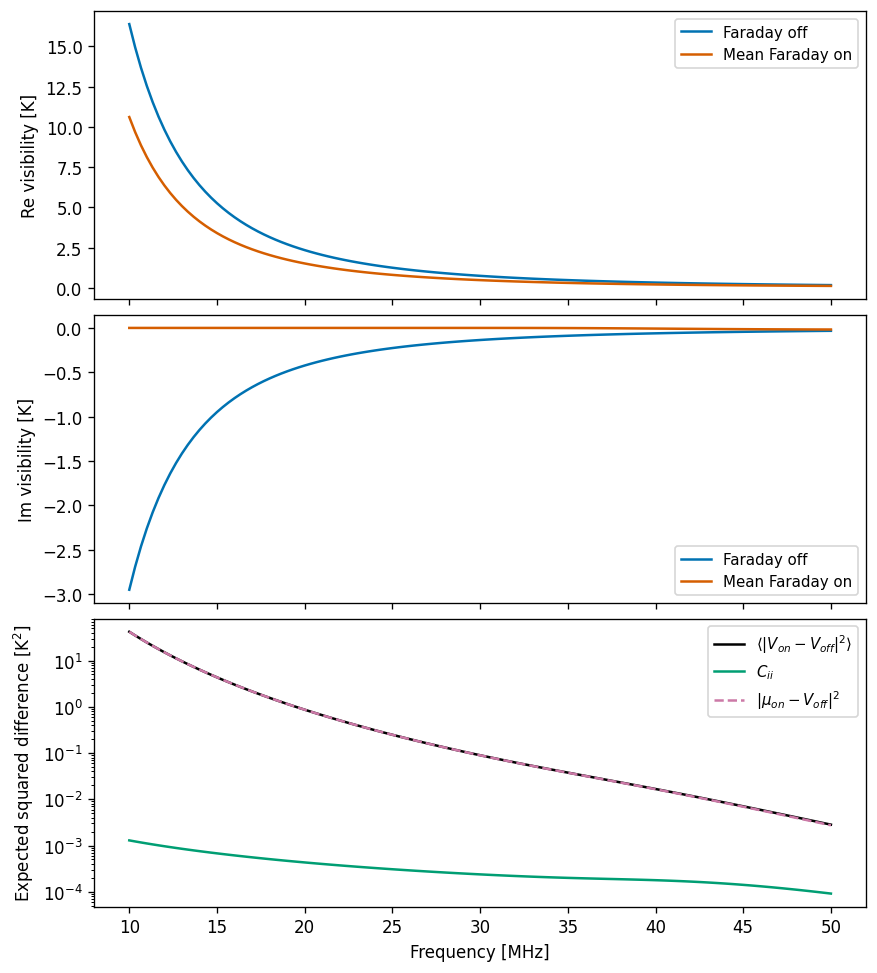

In [4]:
freq = np.linspace(10.0, 50.0, 121)
base = visibility_moments(freq, model, diagonal_only=True)
figures = []
fig, axes = plt.subplots(
    3, 1, figsize=(7.2, 8.0), sharex=True, layout="constrained"
)
for ax, component, name in zip(axes[:2], [np.real, np.imag], ["Re", "Im"]):
    ax.plot(freq, component(base["off"]), color="#0072B2", label="Faraday off")
    ax.plot(
        freq,
        component(base["mean_on"]),
        color="#D55E00",
        label="Mean Faraday on",
    )
    ax.set_ylabel(f"{name} visibility [K]")
    ax.legend(fontsize=9)
mean_difference_power = abs(base["mean_delta"]) ** 2
variance = base["covariance"].real
axes[2].plot(
    freq,
    base["expected_abs_delta2"],
    color="black",
    label=r"$\langle|V_{on}-V_{off}|^2\rangle$",
)
axes[2].plot(freq, variance, color="#009E73", label=r"$C_{ii}$")
axes[2].plot(
    freq,
    mean_difference_power,
    color="#CC79A7",
    ls="--",
    label=r"$|\mu_{on}-V_{off}|^2$",
)
axes[2].set(
    yscale="log",
    ylabel=r"Expected squared difference [K$^2$]",
    xlabel="Frequency [MHz]",
)
axes[2].legend(fontsize=9)
figures.append(("gaussian_screen_step1_off_on", fig))
plt.show()

**Figure 1.** Monochromatic conditional off/on predictions for the baseline
source, ideal complex Jones pair and Gaussian screen defined above (10--50 MHz,
121 samples, no mask). Upper panels retain both complex mean components.
The lower panel is the expected squared paired visibility difference; its
variance and squared mean shift are shown separately. The mean shift can
survive strong suppression of the on mean. This is not a deterministic
screen spectrum, data comparison, or detectability calculation.

## 6. Physical correlation length and wavelength

Vary only $\ell$, leaving screen variance, mean, distance, source and beam
fixed. The dimensionless branch coherence fraction
$\langle|Z_+(x)|^2\rangle=\int WW' e^{-2x^2D_\phi(h)}d^2r\,d^2r'$
measures surviving beam-integrated polarized power relative to the same
unrotated branch. It lies between $|\langle Z_+\rangle|^2$ and 1.
This diagnostic removes the known smooth source spectrum; the second panel
returns to the original visibility difference in K$^2$.

For $\sigma_\phi x\gg1$ and $h_{\rm coh}\ll w$, the small-separation estimate
is $\langle|Z_+|^2\rangle\simeq\ell^2/(8w^2\sigma_\phi^2 x^2)$.
This explains why physical coherence area matters. The plotted curves use
the full model, not this asymptotic estimate. At fixed variance,
$\ell\to0$ drives centered continuum variance to zero; keeping one diagonal
pixel term would instead introduce an arbitrary grid area.

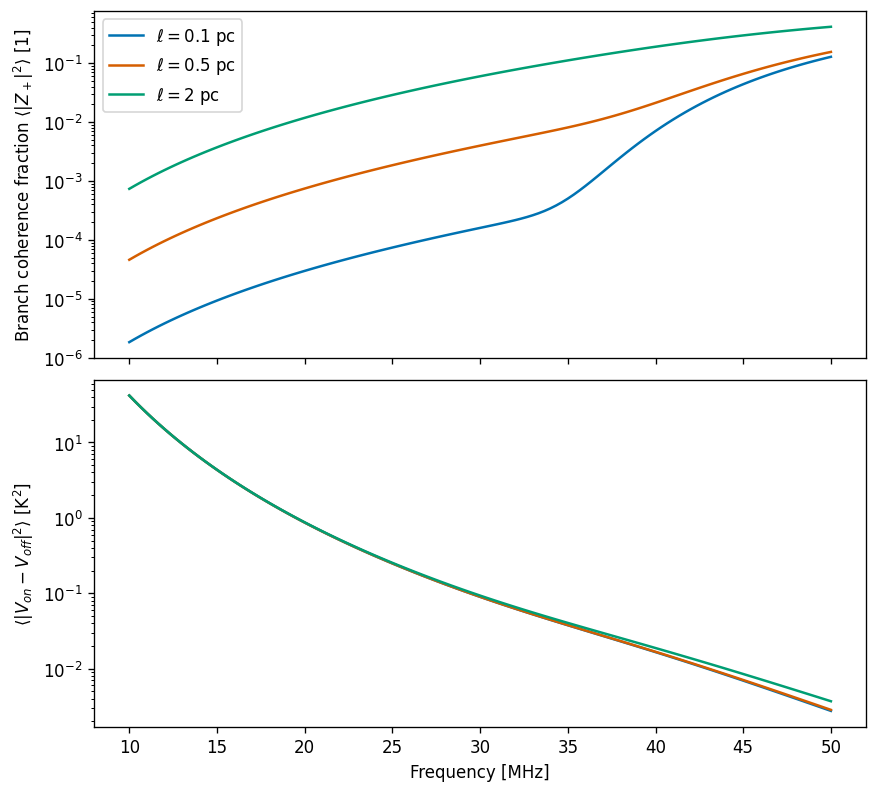

Physical scales; quadrature tolerances do not change these:
  10 MHz: lambda^2= 898.755 m^2, sigma*x=17.975, small-h e-fold estimate=0.019669 pc
  30 MHz: lambda^2=  99.862 m^2, sigma*x= 1.997, small-h e-fold estimate=0.17702 pc
  50 MHz: lambda^2=  35.950 m^2, sigma*x= 0.719, small-h e-fold estimate=0.49173 pc


In [5]:
ell_values = [0.1, 0.5, 2.0]
colors = ["#0072B2", "#D55E00", "#009E73"]
sweeps = {}
fig, axes = plt.subplots(
    2, 1, figsize=(7.2, 6.5), sharex=True, layout="constrained"
)
x = lambda_squared(freq)
for ell, color in zip(ell_values, colors):
    cfg = replace(model, correlation_pc=ell)
    stats = (
        base
        if ell == model.correlation_pc
        else visibility_moments(freq, cfg, diagonal_only=True)
    )
    power = np.array([branch_second_special(v, v, 1, 1, cfg).real for v in x])
    assert np.all((power >= -2e-11) & (power <= 1 + 2e-11))
    sweeps[str(ell)] = dict(stats=stats, power=power)
    axes[0].plot(freq, power, color=color, label=rf"$\ell={ell:g}$ pc")
    axes[1].plot(freq, stats["expected_abs_delta2"], color=color)
# Check all plotted diagonal predictions against the exact reduced integral.
plot_worst = (0.0, None)
for ell, values in sweeps.items():
    cfg = replace(model, correlation_pc=float(ell))
    xx, _, coeff, means = source_terms(freq, cfg)
    for i, lam_sq in enumerate(xx):
        exact_branch = np.array([
            [branch_second_special(lam_sq, lam_sq, s, t, cfg)
             - means[si, i] * means[ti, i].conj()
             for ti, t in enumerate((1, -1))]
            for si, s in enumerate((1, -1))
        ])
        exact_cov = coeff[:, i] @ exact_branch @ coeff[:, i].conj()
        unrotated_scale = np.sum(abs(coeff[:, i]))**2
        error = abs(values['stats']['covariance'][i]-exact_cov)
        normalized_error = float(error/unrotated_scale)
        if normalized_error > plot_worst[0]:
            plot_worst = (normalized_error, [float(ell), float(freq[i])])
assert plot_worst[0] < 2e-9
checks['plotted_diagonal_special_max_scaled_error'] = plot_worst
axes[0].set(
    yscale="log",
    ylabel=r"Branch coherence fraction $\langle|Z_+|^2\rangle$ [1]",
)
axes[0].legend()
axes[1].set(
    yscale="log",
    ylabel=r"$\langle|V_{on}-V_{off}|^2\rangle$ [K$^2$]",
    xlabel="Frequency [MHz]",
)
figures.append(("gaussian_screen_step1_scales", fig))
plt.show()
print("Physical scales; quadrature tolerances do not change these:")
for nu in probe_freq:
    xx = lambda_squared([nu])[0]
    radius = model.correlation_pc / (np.sqrt(2) * model.sigma_depth * xx)
    print(
        f"{nu:4g} MHz: lambda^2={xx:8.3f} m^2, "
        f"sigma*x={model.sigma_depth*xx:6.3f}, "
        f"small-h e-fold estimate={radius:.5g} pc"
    )

**Figure 2.** Full reduced-integral predictions versus frequency for physical
correlation lengths 0.1, 0.5 and 2 pc; all other baseline parameters and
numerical settings are shared. The upper diagnostic is normalized polarized
branch power, explicitly defined above; the lower quantity is the expected
squared original off/on visibility difference. Larger physical correlation
length preserves more on power. The mean term in the difference remains
independent of correlation length. The printed small-separation radius is
only an estimate when $\sigma_\phi x$ is not large. Changing quadrature
accuracy is tested separately and does not represent a change of screen.

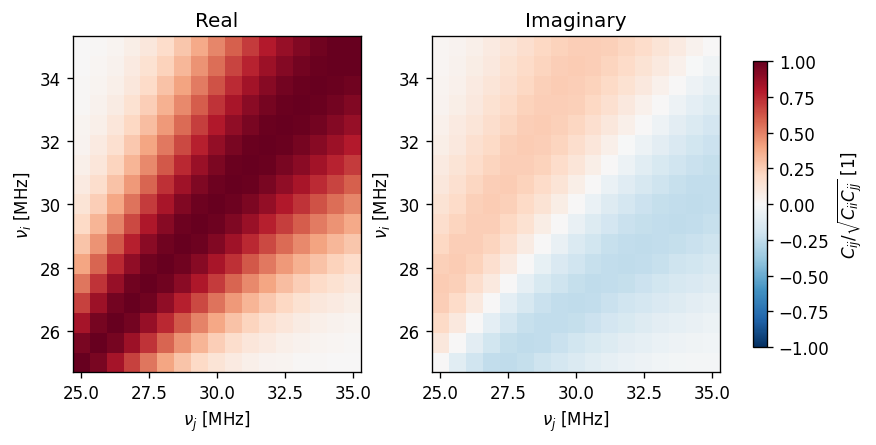

Hermiticity error [K^2]: 1.0926396707304223e-19
Minimum augmented covariance eigenvalue / max |C|: -1.055392608480039e-15


In [6]:
# Full frequency covariance retains phase and both branches.
cov_freq = np.linspace(25.0, 35.0, 17)
full = visibility_moments(cov_freq, model)
cov, relation = full["covariance"], full["relation"]
scale = max(float(np.max(abs(cov))), 1e-30)
hermitian_error = float(np.max(abs(cov - cov.conj().T)))
symmetric_error = float(np.max(abs(relation - relation.T)))
augmented = np.block([[cov, relation], [relation.conj(), cov.conj()]])
minimum_eigenvalue = float(np.linalg.eigvalsh(augmented).min())
assert hermitian_error < 2e-11 * scale
assert symmetric_error < 2e-11 * scale
assert minimum_eigenvalue > -2e-11 * scale
checks["covariance_hermiticity_max_error_K2"] = hermitian_error
checks["relation_symmetry_max_error_K2"] = symmetric_error
checks["augmented_covariance_min_eigenvalue_K2"] = minimum_eigenvalue
checks["augmented_covariance_min_eigenvalue_relative"] = (
    minimum_eigenvalue / scale
)
correlation = cov / np.sqrt(
    cov.diagonal().real[:, None] * cov.diagonal().real[None, :]
)
fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.6), layout="constrained")
# pcolormesh uses the actual frequencies, including their channel widths.
for ax, values, name in zip(
    axes, [correlation.real, correlation.imag], ["Real", "Imaginary"]
):
    im = ax.pcolormesh(
        cov_freq,
        cov_freq,
        values,
        cmap="RdBu_r",
        vmin=-1,
        vmax=1,
        shading="nearest",
        rasterized=True,
    )
    ax.set(xlabel=r"$\nu_j$ [MHz]", ylabel=r"$\nu_i$ [MHz]", title=name)
fig.colorbar(
    im, ax=axes, label=r"$C_{ij}/\sqrt{C_{ii}C_{jj}}$ [1]", shrink=0.85
)
figures.append(("gaussian_screen_step1_covariance", fig))
plt.show()
print("Hermiticity error [K^2]:", hermitian_error)
print(
    "Minimum augmented covariance eigenvalue / max |C|:",
    minimum_eigenvalue / scale,
)

**Figure 3.** Real and imaginary parts of the conditional centered complex
frequency correlation for 17 monochromatic samples over 25--35 MHz, with
the baseline model. $C_{ij}$ is divided by $\sqrt{C_{ii}C_{jj}}$ only for
this display; the saved covariance is in K$^2$. Both panels share the signed
color scale. The imaginary component preserves the relative frequency phase
that a magnitude-only comparison would discard. This is an ensemble model
prediction without channel averaging or measured data.

## 7. Why this does not yet recover the depth-histogram template

For one branch, define
$g(\varphi)=\int W(\mathbf r)\delta(\varphi-\phi(\mathbf r))d^2r$,
including the deterministic source factor separately. Its centered depth
covariance involves
\[
C_g(\varphi,\varphi')=\iint WW'
[p_2(\varphi,\varphi';\rho(h))-p_1(\varphi)p_1(\varphi')]d^2r\,d^2r'.
\]
A one-point RM histogram supplies $p_1$ but not the correlated $p_2$.
At finite physical $\ell$, this is generally not
$A_{\rm power}^2H(\varphi)\delta(\varphi-\varphi')$.
Recovering that existing template requires a separate physical assumption
of uncorrelated **centered depth amplitudes**, their power density and
normalization. It also requires retaining any mean signal and, for a complex
visibility, both branches and their joint statistics.

After removing the known smooth source spectrum, the independent-depth
covariance depends only on $x-x'$. This screen result additionally depends
on $xx'$; even its same-frequency power varies with $x$. A narrow-band
approximation could freeze $xx'$ and the physical coherence weighting at a
reference frequency, but its error must be bounded in each band. That step
has not been tested here. Neither a stable RM histogram nor an infinitesimal
independent-pixel limit sets the physical amplitude. RM reconstruction
uncertainty is not automatically physical sub-beam turbulence.

## 8. What step 2 must falsify, and what remains unvalidated

The [implementation plan](../docs/plans/2026-10-15-gaussian-screen-step1.md)
predeclares the next comparison:

1. Independently generate screens with this covariance, checking spectral
   normalization, domain/wraparound and Fourier-cutoff errors. Pin the
   physical Fourier realization across angular refinements. Start with the
   same baseline at 45, 47.5 and 50 MHz, and zero/constant-screen controls.
2. Compute the **original** on/off Stokes/Jones angular integral by independent
   Cartesian quadrature. Require three refinement levels and maximum
   per-realization shifts below $10^{-4}$ of unrotated polarized amplitude
   for both final refinements. Refine the domain/screen spectrum separately.
3. Only then increase independent ensemble size and estimate sampling errors
   by independent batches or bootstrap over screens. Compare every real and
   imaginary mean/covariance component, raw second moment, relation matrix,
   and squared on-minus-off difference without fitting any amplitude.
   Report numerical error bounds, per-cell Monte Carlo errors and the worst
   discrepancy. The plan specifies a multiple-comparison gate and keeps
   numerical error distinct from ensemble error.

Failure of angular convergence rejects a direct reference; failure of the
moment comparison after convergence rejects this implementation or model
specification. Passing these tests would validate this conditional toy model,
not the Galaxy. Strong-rotation deterministic tests, Galactic correlations,
curved sky/spin transport, mixed emission/rotation, real LuSEE beams/loading,
channel integration, foreground treatment, noise and forecast amplitudes
remain unvalidated. The illustrative strong-rotation curves above do not
complete step 3. No long real-beam audit or ensemble has been launched.

## 9. Configuration, code provenance and reproducible products

All displayed numbers and figure copies below are generated in this run.
The numerical artifacts are keyed by a SHA256 of effective source hashes,
physical/numerical configurations, frequencies and software versions; no
old cache is loaded. The notebook input hash records its Markdown and code
cells while excluding outputs. The git revision describes the base commit;
source hashes identify the effective working-tree code, including untracked
files. The execution record also includes UTC, Python executable, runtime and
peak resident memory. This provenance does not establish physical validity.

In [7]:
source_files = [
    "AGENTS.md",
    "TODO.md",
    "PROGRESS.md",
    "docs/paper-preparation.md",
    "docs/specs/2026-10-15-gaussian-screen-step1.md",
    "docs/plans/2026-10-15-gaussian-screen-step1.md",
    "src/lusee_faraday/gaussian_screen.py",
    "src/lusee_faraday/config.py",
    "src/lusee_faraday/conventions.py",
    "src/lusee_faraday/__init__.py",
    "tests/test_gaussian_screen.py",
    "scripts/gaussian_screen_step1.py",
    "pyproject.toml",
    "uv.lock",
]
source_hashes = {
    p: hashlib.sha256((ROOT / p).read_bytes()).hexdigest()
    for p in source_files
}
notebook = nbformat.read(
    ROOT / "notebooks/gaussian_screen_step1.ipynb", as_version=4
)
input_cells = [(cell.cell_type, cell.source) for cell in notebook.cells]
notebook_input_hash = hashlib.sha256(
    json.dumps(input_cells).encode()
).hexdigest()
versions = {
    p: metadata.version(p)
    for p in [
        "numpy",
        "scipy",
        "matplotlib",
        "nbformat",
        "nbclient",
        "ipykernel",
        "lusee",
        "croissant-sim",
        "jax",
    ]
}
configuration = dict(
    model=asdict(model),
    numerical=asdict(numerical),
    tightened_numerical=asdict(tight),
    frequency_mhz=freq.tolist(),
    covariance_frequency_mhz=cov_freq.tolist(),
    correlation_sweep_pc=ell_values,
    probe_frequency_mhz=probe_freq.tolist(),
    versions=versions,
    source_sha256=source_hashes,
    notebook_input_sha256=notebook_input_hash,
)
fingerprint = hashlib.sha256(
    json.dumps(configuration, sort_keys=True).encode()
).hexdigest()
out = ROOT / "generated_data/gaussian_screen_step1"
out.mkdir(parents=True, exist_ok=True)
figure_dir = ROOT / "report/figures"
figure_dir.mkdir(parents=True, exist_ok=True)
figure_hashes = {}
for name, fig in figures:
    for suffix in ["pdf", "png"]:
        path = figure_dir / f"{name}.{suffix}"
        fig.savefig(
            path, dpi=160, metadata={"Creator": "gaussian_screen_step1.py"}
        )
        figure_hashes[str(path.relative_to(ROOT))] = hashlib.sha256(
            path.read_bytes()
        ).hexdigest()
arrays = dict(
    frequency_mhz=freq,
    covariance_frequency_mhz=cov_freq,
    off=base["off"],
    mean_on=base["mean_on"],
    mean_delta=base["mean_delta"],
    diagonal_covariance=base["covariance"],
    expected_abs_delta2=base["expected_abs_delta2"],
    covariance=full["covariance"],
    relation=full["relation"],
    second_on=full["second_on"],
    second_off=full["second_off"],
    second_on_off=full["second_on_off"],
    second_delta=full["second_delta"],
    second_on_nonconjugated=full["second_on_nonconjugated"],
)
for ell, values in sweeps.items():
    arrays[f"ell_{ell}_branch_power"] = values["power"]
    arrays[f"ell_{ell}_expected_abs_delta2"] = values["stats"][
        "expected_abs_delta2"
    ]
np.savez_compressed(out / f"{fingerprint}.npz", **arrays)
record = dict(
    configuration=configuration,
    fingerprint=fingerprint,
    utc=datetime.now(timezone.utc).isoformat(),
    python=platform.python_version(),
    executable=sys.executable,
    git_head=subprocess.check_output(
        ["git", "rev-parse", "HEAD"], text=True
    ).strip(),
    git_status=subprocess.check_output(
        ["git", "status", "--short"], text=True
    ),
    checks=checks,
    figure_sha256=figure_hashes,
    numerical_product_sha256=hashlib.sha256(
        (out / f"{fingerprint}.npz").read_bytes()
    ).hexdigest(),
    runtime_seconds=time.monotonic() - started,
    kernel_peak_rss_mib=resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
    / 1024,
    scope=("Step 1: algebra and reduced integration only; "
           "no spatial screen ensemble"),
)
(out / f"{fingerprint}.json").write_text(json.dumps(record, indent=2) + "\n")
(ROOT / "docs/gaussian-screen-step1-results.json").write_text(
    json.dumps(record, indent=2) + "\n"
)
print(json.dumps(record, indent=2))
print("All step-1 assertions passed. STOP: step 2 awaits review.")

{
  "configuration": {
    "model": {
      "distance_pc": 100.0,
      "correlation_pc": 0.5,
      "mean_depth": 0.01,
      "sigma_depth": 0.02,
      "beam_sigma_deg": 1.0,
      "source_sigma_deg": 1.5,
      "i_ref_k": 2.0,
      "p_ref_k": 1.0,
      "angle_deg": 20.0,
      "ref_mhz": 30.0,
      "beta": -2.8,
      "jones_angle_deg": 45.0,
      "jones_phase_deg": 60.0
    },
    "numerical": {
      "epsabs": 2e-11,
      "epsrel": 2e-10,
      "upper_u": 40.0
    },
    "tightened_numerical": {
      "epsabs": 2e-13,
      "epsrel": 2e-12,
      "upper_u": 48.0
    },
    "frequency_mhz": [
      10.0,
      10.333333333333334,
      10.666666666666666,
      11.0,
      11.333333333333334,
      11.666666666666666,
      12.0,
      12.333333333333332,
      12.666666666666666,
      13.0,
      13.333333333333332,
      13.666666666666666,
      14.0,
      14.333333333333332,
      14.666666666666666,
      15.0,
      15.333333333333332,
      15.666666666666666,
      1